# Этап 7. Время эпизода и реальный объем прогонов

Код: `rssrl/volume.py`. Проверки: `tests/test_volume.py`.

Вопросы этапа:
1. Сколько считается один эпизод на одном ядре и при параллельном счете?
2. Куда уходит время — в наш код или в highway-env?
3. Сколько сцен нужно на уровень β, чтобы классифицировать исходы (хуже / лучше / эквивалентно / неопределенно) с поправкой Холма?
4. Сколько займут оценка и обучение PPO на этом компьютере?

Числа ниже зависят от компьютера и его загрузки: это порядок величин, а не константы.

In [1]:
import sys
sys.path.insert(0, '..')
import os, time, cProfile, pstats
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid
from rssrl.responsibility import responsibility_table
from rssrl.scenarios import make_scene, run_episode
from rssrl.volume import (time_episodes, discordance, episodes_needed,
                          min_detectable, holm_z, evaluation_plan)

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_07'  # таблицы пилота, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
print('ядер (логических):', os.cpu_count(), '| загрузка (1 мин):', round(os.getloadavg()[0], 1))

ядер (логических): 8 | загрузка (1 мин): 151.1


## 1. Время эпизода на одном ядре

In [2]:
setups = [
    ('nominal', (1.0, False, 0.0), 'номинальный, без фильтра'),
    ('nominal', (1.0, True, 0.5), 'номинальный, фильтр ρ'),
    ('brake', (2.0, True, 0.5), 'тормозящий β = 2, фильтр, задержка ρ'),
]
frames = []
for kind, (level, shield, delay), label in setups:
    t = time_episodes([(s, level, shield, delay) for s in range(8)], kind)
    t['вариант'] = label
    frames.append(t)
single = pd.concat(frames)
single['с счета на 1 с симуляции'] = single.wall_s / single.sim_s
single.groupby('вариант', sort=False).agg(
    эпизодов=('wall_s', 'size'),
    счет_с=('wall_s', 'mean'),
    симуляция_с=('sim_s', 'mean'),
    счет_на_1с_симуляции=('с счета на 1 с симуляции', 'mean'),
).round(3)

,эпизодов,счет_с,симуляция_с,счет_на_1с_симуляции
вариант,,,,
"номинальный, без фильтра",8,2.961,20.875,0.146
"номинальный, фильтр ρ",8,5.375,40.000,0.134
"тормозящий β = 2, фильтр, задержка ρ",8,4.993,40.000,0.125


Время пропорционально длине эпизода в секундах симуляции: эпизод без фильтра короче, потому что заканчивается столкновением. Полный эпизод 40 с — около 5 с счета на одном ядре (прошлый замер ≈ 4 с; этот сделан при сильной посторонней загрузке компьютера, см. загрузку в первой ячейке).

## 2. Куда уходит время

In [3]:
pr = cProfile.Profile()
pr.enable()
run_episode(make_scene(5, shield=True, kind='nominal'))
pr.disable()
st = pstats.Stats(pr)
total = sum(v[2] for v in st.stats.values())  # собственное время всех функций
def group(path):
    if 'rssrl' in path: return 'наш код (rssrl: фильтр, нарушители, логгер)'
    if 'highway_env' in path: return 'highway-env (фон, столкновения, дорога)'
    if 'numpy' in path: return 'numpy (вызывается из highway-env и нашего кода)'
    return 'прочее (Python, gymnasium)'
share = {}
for (path, _, _), v in st.stats.items():
    share[group(path)] = share.get(group(path), 0) + v[2]
(pd.Series(share) / total).sort_values(ascending=False).round(3).to_frame('доля времени')

,доля времени
"highway-env (фон, столкновения, дорога)",0.659
"прочее (Python, gymnasium)",0.164
numpy (вызывается из highway-env и нашего кода),0.162
"наш код (rssrl: фильтр, нарушители, логгер)",0.015


Основное время уходит на сам highway-env: каждая из 50 фоновых машин на каждом из 600 шагов ищет соседей (IDM, MOBIL) и проверяет столкновения со всеми. Наш фильтр, нарушители и логгер — малая доля. Поэтому ускорять наш код бессмысленно, а уменьшать число машин или частоту симуляции нельзя: это изменит сам эксперимент.

## 3. Параллельный счет и пилот по сетке β

Основной эксперимент в миниатюре: 50 сцен × 6 уровней β × 3 варианта (фильтр с задержкой ρ и 0, без фильтра), агент IDLE вместо PPO, нарушение по расписанию (одинаковый момент для всех вариантов). d_min фильтра — лемма 2 с учетом рывка. Рядом — тот же пилот с d_min как в статье (старый вариант). Это одновременно замер скорости параллельного счета и источник оценки разброса для расчета объема.

In [4]:
BETAS = [1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
# основной режим — фильтр с задержкой ρ, дополнительный — мгновенный фильтр
VARIANTS = [(True, 0.5), (True, 0.0), (False, 0.5)]
NAMES = {(True, 0.5): 'фильтр, задержка ρ (основной)', (True, 0.0): 'фильтр, задержка 0 (доп.)',
         (False, 0.5): 'без фильтра'}
t0 = time.perf_counter()
grid, grid_logs = run_grid(range(50), BETAS, VARIANTS, kind='brake', trigger='schedule')
wall = time.perf_counter() - t0
grid['вариант'] = [NAMES[(s, d)] for s, d in zip(grid.shield, grid.reaction_delay)]
grid.drop(columns=['crash_partners']).to_csv(PILOT / 'beta_grid.csv', index=False)
THROUGHPUT = grid.t_end.sum() / wall  # секунд симуляции за секунду счета
print(f'{len(grid)} эпизодов за {wall / 60:.1f} мин; '
      f'{THROUGHPUT:.1f} с симуляции за 1 с счета; '
      f'полный эпизод 40 с ≈ {40 / THROUGHPUT:.2f} с при параллельном счете')

900 эпизодов за 20.5 мин; 23.1 с симуляции за 1 с счета; полный эпизод 40 с ≈ 1.73 с при параллельном счете


In [5]:
# старый вариант: d_min по лемме 2 как в статье, те же сцены и то же расписание
old, old_logs = run_grid(range(50), BETAS, VARIANTS[:2], kind='brake', trigger='schedule', dmin='lemma2')
old['вариант'] = [NAMES[(s, d)] for s, d in zip(old.shield, old.reaction_delay)]
old.drop(columns=['crash_partners']).to_csv(PILOT / 'beta_grid_lemma2.csv', index=False)
pd.concat({'d_min с учетом рывка (новый)': grid.pivot_table(index='вариант', columns='beta', values='collision', aggfunc='sum', sort=False),
           'd_min леммы 2 как в статье (старый)': old.pivot_table(index='вариант', columns='beta', values='collision', aggfunc='sum', sort=False)},
          names=['формула d_min в фильтре'])

beta                                                               1.0  1.2  \
формула d_min в фильтре             вариант                                   
d_min с учетом рывка (новый)        фильтр, задержка ρ (основной)    0    0   
                                    фильтр, задержка 0 (доп.)        0    0   
                                    без фильтра                     49   49   
d_min леммы 2 как в статье (старый) фильтр, задержка ρ (основной)   40   38   
                                    фильтр, задержка 0 (доп.)        0    0   

beta                                                               1.4  1.6  \
формула d_min в фильтре             вариант                                   
d_min с учетом рывка (новый)        фильтр, задержка ρ (основной)    0    0   
                                    фильтр, задержка 0 (доп.)        0    0   
                                    без фильтра                     49   49   
d_min леммы 2 как в статье (старый) фильтр, задержка ρ (основной)   42   42   
                                    фильтр, задержка 0 (доп.)        0    0   

beta                                                               1.8  2.0  
формула d_min в фильтре             вариант                                  
d_min с учетом рывка (новый)        фильтр, задержка ρ (основной)    0    0  
                                    фильтр, задержка 0 (доп.)        0    0  
                                    без фильтра                     49   49  
d_min леммы 2 как в статье (старый) фильтр, задержка ρ (основной)   41   40  
                                    фильтр, задержка 0 (доп.)        0    0

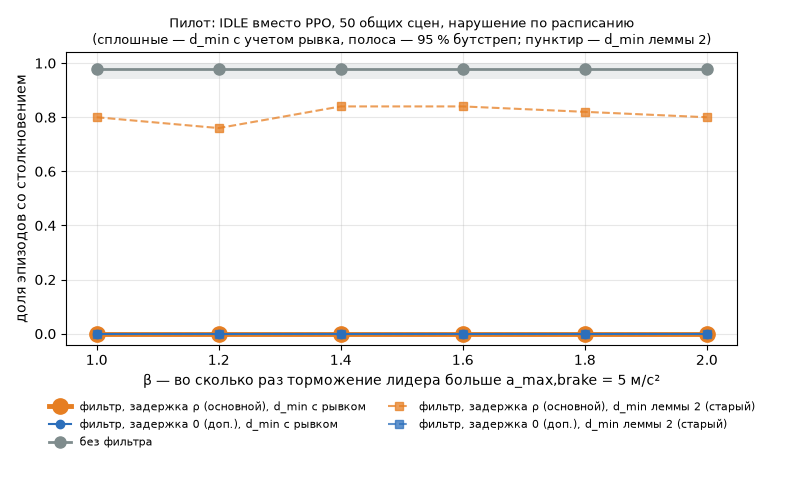

In [6]:
# доля столкновений с 95 % бутстреп-интервалом по сценам (одна «политика» — IDLE)
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 4.8))
colors = {(False, 0.5): '#7f8c8d', (True, 0.0): '#2c6fbb', (True, 0.5): '#e67e22'}
# ρ рисуем крупнее и раньше, чтобы на нуле была видна и она, и линия задержки 0
style = {(True, 0.5): (11, 3.5), (True, 0.0): (6, 1.5), (False, 0.5): (8, 2)}
for key, name in NAMES.items():
    sub = grid[(grid.shield == key[0]) & (grid.reaction_delay == key[1])]
    mat = sub.pivot(index='seed', columns='beta', values='collision').astype(float)[BETAS].to_numpy()
    boot = mat[rng.integers(0, len(mat), (2000, len(mat)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    m = mat.mean(axis=0)
    ms, lw = style[key]
    ax.plot(BETAS, m, 'o-', color=colors[key], linewidth=lw, markersize=ms,
            label=name + (', d_min с рывком' if key[0] else ''))
    ax.fill_between(BETAS, lo, hi, color=colors[key], alpha=0.15, linewidth=0)
for key, name in list(NAMES.items())[:2]:
    sub = old[(old.shield == key[0]) & (old.reaction_delay == key[1])]
    m = sub.pivot(index='seed', columns='beta', values='collision').astype(float)[BETAS].mean().to_numpy()
    ax.plot(BETAS, m, 's--', color=colors[key], linewidth=1.5, markersize=6, alpha=0.75,
            label=name + ', d_min леммы 2 (старый)')
ax.set_xlabel('β — во сколько раз торможение лидера больше a_max,brake = 5 м/с²')
ax.set_ylabel('доля эпизодов со столкновением')
ax.set_ylim(-0.04, 1.04)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.set_title('Пилот: IDLE вместо PPO, 50 общих сцен, нарушение по расписанию\n'
             '(сплошные — d_min с учетом рывка, полоса — 95 % бутстреп; пунктир — d_min леммы 2)', fontsize=9)
fig.tight_layout()
fig.savefig(FIG / '07_pilot_beta_grid.png', dpi=150)

Это пилот без RL, но он показывает главное изменение. **С d_min, учитывающей рывок**, у фильтра 0 столкновений из 50 на каждом уровне β от 1 до 2, при обеих задержках: агент держит дистанцию с запасом на набор торможения, а при β > 1 добавляется экстренное торможение 8 м/с². **С d_min леммы 2 как в статье** при задержке ρ столкновения 36–42 из 50 на каждом уровне, включая β = 1: медленные въезды в стоящего нарушителя, по правилам RSS почти все «не установлено». Без фильтра IDLE врезается всегда.

Отрицательный результат допустим: при агенте IDLE + фильтр превышение торможения лидера до β = 2 (10 м/с²) в этой сцене к столкновениям не приводит, β* на сетке не достигнуто. С PPO, которая сама выбирает дистанцию и скорость, картина может быть другой. Если и с PPO столкновений не будет, вопрос к преподавателю — расширять ли сетку (10 м/с² — выбранный предел испытаний) или делать сцену жестче (например, нарушение при меньшем зазоре).

In [7]:
# ответственность за столкновения в пилоте по сетке β
resp = pd.concat([responsibility_table(grid, grid_logs).assign(формула='с рывком'),
                  responsibility_table(old, old_logs).assign(формула='лемма 2')], ignore_index=True)
resp['вариант'] = [NAMES[(s, d)] for s, d in zip(resp['shield'], resp['reaction_delay'])]
resp.to_csv(PILOT / 'beta_grid_responsibility.csv', index=False)
(resp.pivot_table(index=['формула', 'вариант', 'responsible'], columns='level', values='seed',
                  aggfunc='size', fill_value=0, sort=False)
     .rename_axis(index=['формула d_min', 'вариант', 'отвечает'], columns='β'))

β                                                           1.0  1.2  1.4  \
формула d_min вариант                       отвечает                        
с рывком      без фильтра                   агент            48   10   10   
                                            оба               1   39   39   
лемма 2       фильтр, задержка ρ (основной) не установлено   40   38   42   
                                            нарушитель        0    0    0   

β                                                           1.6  1.8  2.0  
формула d_min вариант                       отвечает                       
с рывком      без фильтра                   агент            10   10   10  
                                            оба              39   39   39  
лемма 2       фильтр, задержка ρ (основной) не установлено   42   39   36  
                                            нарушитель        0    2    4

## 3а. Парность сцен: одинаков ли момент нарушения у разных вариантов агента

Сейчас нарушение начинается по условию на зазор (агент идет за машиной с зазором ≤ 1,1·d_min). Зазор зависит от того, как ехал агент: с фильтром агент мог раньше притормозить, без фильтра — нет. Тогда у вариантов агента на одной и той же сцене момент нарушения (и даже машина-нарушитель) могут различаться, и сравнение перестает быть строго парным. Проверяем на 50 сценах (β = 1; до нарушения β ни на что не влияет), сравнивая с основным вариантом (фильтр, задержка ρ).

Альтернатива — нарушение **по расписанию** (`trigger='schedule'`): момент и машина берутся из эталонного прогона (IDLE + фильтр ρ) и одинаковы для всех вариантов агента.

In [8]:
del grid_logs, old_logs  # освобождаем память
pair = {}
for trig in ['gap', 'schedule']:
    o, _ = run_grid(range(50), [1.0, 2.0], VARIANTS, kind='brake', trigger=trig)
    o['вариант'] = [NAMES[(s, d)] for s, d in zip(o.shield, o.reaction_delay)]
    pair[trig] = o
rows = []
for trig, o in pair.items():
    b1 = o[o.beta == 1.0]
    t = b1.pivot(index='seed', columns='вариант', values='t_trigger')
    u = b1.pivot(index='seed', columns='вариант', values='violator_uid')
    ref = NAMES[(True, 0.5)]
    for name in [NAMES[(True, 0.0)], NAMES[(False, 0.5)]]:
        same_t = ((t[name] - t[ref]).abs() < 1e-6) | (t[name].isna() & t[ref].isna())
        same_u = (u[name] == u[ref]) | (u[name].isna() & u[ref].isna())
        rows.append({'момент нарушения': 'по зазору' if trig == 'gap' else 'по расписанию',
                     'вариант (сравнение с основным)': name,
                     'тот же момент, сцен из 50': int(same_t.sum()),
                     'та же машина, сцен из 50': int(same_u.sum()),
                     'медиана |Δt|, с': round(float((t[name] - t[ref]).abs().median()), 2),
                     'макс |Δt|, с': round(float((t[name] - t[ref]).abs().max()), 2)})
pd.DataFrame(rows)

,момент нарушения,вариант (сравнение с основным),"тот же момент, сцен из 50","та же машина, сцен из 50","медиана |Δt|, с","макс |Δt|, с"
0,по зазору,"фильтр, задержка 0 (доп.)",2,2,3.93,19.93
1,по зазору,без фильтра,2,45,3.47,21.13
2,по расписанию,"фильтр, задержка 0 (доп.)",50,50,0.00,0.00
3,по расписанию,без фильтра,42,42,0.00,0.00


In [9]:
# влияет ли способ выбора момента на число столкновений
pd.concat({('по зазору' if k == 'gap' else 'по расписанию'):
           o.pivot_table(index='вариант', columns='beta', values='collision', aggfunc='sum', sort=False)
           for k, o in pair.items()}, names=['момент нарушения'])

beta                                            1.0  2.0
момент нарушения вариант                                
по зазору        фильтр, задержка ρ (основной)    0    0
                 фильтр, задержка 0 (доп.)        0    0
                 без фильтра                     49   49
по расписанию    фильтр, задержка ρ (основной)    0    0
                 фильтр, задержка 0 (доп.)        0    0
                 без фильтра                     49   49

In [10]:
# по расписанию: был ли нарушитель в момент нарушения машиной впереди агента
s = pair['schedule']
s[s.beta == 1.0].groupby('вариант', sort=False)['violator_was_front'].agg(['sum', 'size'])

,sum,size
вариант,,
"фильтр, задержка ρ (основной)",50,50
"фильтр, задержка 0 (доп.)",47,50
без фильтра,41,50


Итог по парности:
- **По зазору** с новой формулой момент нарушения у мгновенного фильтра и у агента без фильтра совпадает с основным вариантом только в 2 сценах из 50, расхождение до ≈ 20 с. Причина: агент с новой d_min держится дальше, и условие «зазор ≤ 1,1·d_min» наступает в другое время или с другой машиной. Сравнение по зазору уже не парное.
- **По расписанию** момент и машина одинаковы во всех сценах, где нарушение вообще случилось (без фильтра в 8 сценах агент врезался раньше момента нарушения). Нарушитель в этот момент был машиной впереди агента в 50 / 47 / 41 сценах из 50 (основной вариант / мгновенный фильтр / без фильтра).

Плюсы расписания: одно и то же воздействие на все варианты агента (настоящие общие случайные числа), разница в исходах — только от агента; агент, который держит большую дистанцию, получает за это честный выигрыш. Минусы: если агент едет иначе, чем эталон (перестроится, отстанет), нарушитель может оказаться не перед ним, и испытание для этого варианта будет мягче; «трудность» сцены зависит от выбора эталонного агента (для основного эксперимента предлагаем IDM/MOBIL + RSS — он есть во всех сравнениях и не зависит от seed обучения). Плюсы условия по зазору: каждый вариант испытывается в одинаково критической ситуации. Минусы: пары не строгие, а у осторожного агента нарушение может не наступить вовсе. Рекомендация: основной эксперимент — по расписанию, долю сцен, где нарушитель оказался машиной впереди, — в отчет.

## 4. Сколько сцен нужно на уровень

Сравнения парные: уровень β и β = 1 на одних и тех же сценах. Разброс парной разности определяется долей **несовпадающих пар** d — сцен, где на одном уровне столкновение есть, а на другом нет. Половина ДИ разности ≈ z·√(d/n).

Поправка Холма: сравнений в основной части 5 уровней (β > 1 против β = 1) × 5 вариантов (RL без фильтра; IDM/MOBIL+RSS и RL+RSS — каждый при двух задержках) = 25. Для объема берем самый строгий шаг Холма (уровень 0,05/25).

In [11]:
M = 25
Z = holm_z(M)
print(f'z для 1 сравнения: {holm_z(1):.2f}; z с поправкой Холма (m = {M}, худший шаг): {Z:.2f}')
disc = []
for (sh, d), name in NAMES.items():
    if not sh:
        continue
    sub = grid[grid.shield & (grid.reaction_delay == d)].pivot(index='seed', columns='beta', values='collision')
    disc.append(pd.Series({b: discordance(sub[b], sub[1.0]) for b in BETAS[1:]}, name=name))
disc = pd.DataFrame(disc)
disc.columns = [f'β = {b:g}' for b in BETAS[1:]]
disc.round(2)  # доля несовпадающих пар с β = 1

z для 1 сравнения: 1.96; z с поправкой Холма (m = 25, худший шаг): 3.09


,β = 1.2,β = 1.4,β = 1.6,β = 1.8,β = 2
"фильтр, задержка ρ (основной)",0.0,0.0,0.0,0.0,0.0
"фильтр, задержка 0 (доп.)",0.0,0.0,0.0,0.0,0.0


Два разных требования к объему:
- **«Хуже»** (весь ДИ разности > 0) — легко, когда эффект большой. Наименьший эффект, который при n сценах можно назвать «хуже»: δ_min ≈ z²/(n + z²).
- **«Эквивалентно»** (весь ДИ в пределах ±2 п.п.) — трудно: нужно n ≈ z²·d / 0,02². Достижимо только при малом d, то есть там, где эффекта почти нет.

In [12]:
rows = []
for n in (100, 300, 500, 1000, 2000):
    rows.append({'сцен на уровень': n,
                 'δ_min «хуже», п.п. (без поправки)': round(100 * min_detectable(n), 1),
                 'δ_min «хуже», п.п. (Холм)': round(100 * min_detectable(n, Z), 1),
                 'эквивалентность ±2 п.п. возможна при d ≤, п.п. (Холм)': round(100 * n * 0.02 ** 2 / Z ** 2, 2)})
pd.DataFrame(rows).set_index('сцен на уровень')

,"δ_min «хуже», п.п. (без поправки)","δ_min «хуже», п.п. (Холм)","эквивалентность ±2 п.п. возможна при d ≤, п.п. (Холм)"
сцен на уровень,,,
100,3.7,8.7,0.42
300,1.3,3.1,1.26
500,0.8,1.9,2.09
1000,0.4,0.9,4.19
2000,0.2,0.5,8.38


In [13]:
need = pd.DataFrame({
    f'±{w * 100:g} п.п.': [episodes_needed(d, w, Z) for d in (0.01, 0.02, 0.05, 0.1, 0.2)]
    for w in (0.02, 0.03, 0.05)
}, index=[f'd = {d:g}' for d in (0.01, 0.02, 0.05, 0.1, 0.2)])
need.index.name = 'несовпадающих пар'
need  # сцен на уровень, чтобы половина ДИ (с Холмом) была не шире указанной

,±2 п.п.,±3 п.п.,±5 п.п.
несовпадающих пар,,,
d = 0.01,239,107,39
d = 0.02,478,213,77
d = 0.05,1194,531,191
d = 0.1,2388,1062,382
d = 0.2,4775,2123,764


Вывод для плана: **500 сцен на уровень** — разумный компромисс. При нем:
- «хуже» обнаруживается начиная с разности ≈ 2 п.п. (с поправкой Холма);
- «эквивалентно» в пределах ±2 п.п. можно показать, если несовпадающих пар не больше ≈ 2 %. В пилоте с новой формулой их 0 (столкновений нет ни на одном уровне), то есть для IDLE + фильтр результат был бы «эквивалентно» на всех уровнях.

**Оговорка.** Это расчет для одной политики. По замечанию 8 бутстреп двухуровневый: сначала политики (seed обучения), затем сцены. Разброс между политиками PPO до обучения неизвестен; если он большой, сужать ДИ нужно числом политик, а не сцен.

## 5. Сколько займет оценка

In [14]:
mean_sim = grid.t_end.mean()  # в пилоте часть эпизодов короче 40 с из-за столкновений
rows = []
for k in (3, 5):
    for n in (300, 500, 1000):
        plan = evaluation_plan(n_scenes=n, n_policies=k)
        ep = plan['эпизодов всего']
        rows.append({'политик на тип (seed обучения)': k, 'сцен на уровень': n,
                     'эпизодов на сцену и уровень': plan['эпизодов на сцену и уровень'],
                     'эпизодов всего': ep,
                     'часов (все эпизоды по 40 с)': round(ep * 40 / THROUGHPUT / 3600, 1),
                     f'часов (средняя длина как в пилоте, {mean_sim:.0f} с)': round(ep * mean_sim / THROUGHPUT / 3600, 1)})
pd.DataFrame(rows).set_index(['политик на тип (seed обучения)', 'сцен на уровень'])

эпизодов на сцену и уровень  \
политик на тип (seed обучения) сцен на уровень                                
3                              300                                       20   
                               500                                       20   
                               1000                                      20   
5                              300                                       32   
                               500                                       32   
                               1000                                      32   

                                                эпизодов всего  \
политик на тип (seed обучения) сцен на уровень                   
3                              300                       60000   
                               500                      100000   
                               1000                     200000   
5                              300                       96000   
                               500                      160000   
                               1000                     320000   

                                                часов (все эпизоды по 40 с)  \
политик на тип (seed обучения) сцен на уровень                                
3                              300                                     28.9   
                               500                                     48.1   
                               1000                                    96.2   
5                              300                                     46.2   
                               500                                     77.0   
                               1000                                   154.0   

                                                часов (средняя длина как в пилоте, 32 с)  
политик на тип (seed обучения) сцен на уровень                                            
3                              300                                                  22.8  
                               500                                                  38.0  
                               1000                                                 76.0  
5                              300                                                  36.5  
                               500                                                  60.8  
                               1000                                                121.7

Что входит: 6 уровней β + 4 уровня γ; на каждую сцену и уровень — 2 типа политик PPO × k seed обучения, каждая с фильтром и без (схема 2×2), плюс IDM/MOBIL+RSS без RL; варианты с фильтром — при двух задержках. Дополнительный эксперимент 2 и контрфактические прогоны сюда не входят (их делаем на ~100 сценах).

Вариант «5 политик × 500 сцен» при замеренных 23 с симуляции за 1 с счета (замер при посторонней загрузке; в прошлый раз 26–35) — 61–77 часов, то есть около 3 суток. Его можно разбить на ночные прогоны по уровням.

## 6. Сколько займет обучение PPO

In [15]:
from rssrl.volume import ppo_steps_per_second
speed = {n: ppo_steps_per_second(n) for n in (1, 8)}
print({f'{k} сред': f'{v:.1f} шагов/с' for k, v in speed.items()})

{'1 сред': '9.4 шагов/с', '8 сред': '30.6 шагов/с'}


In [16]:
rows = []
for budget in (2e4, 1e5, 2e5):
    per_policy_h = budget / speed[8] / 3600
    rows.append({'шагов обучения на политику': f'{budget:.0e}',
                 'часов на 1 политику': round(per_policy_h, 1),
                 'часов на 2 типа × 3 seed': round(6 * per_policy_h, 1),
                 'часов на 2 типа × 5 seed': round(10 * per_policy_h, 1)})
pd.DataFrame(rows).set_index('шагов обучения на политику')

,часов на 1 политику,часов на 2 типа × 3 seed,часов на 2 типа × 5 seed
шагов обучения на политику,,,
2e+04,0.2,1.1,1.8
1e+05,0.9,5.4,9.1
2e+05,1.8,10.9,18.2


Шаг обучения — одно решение политики (1 с симуляции, 15 шагов физики). Замер сделан на обычной highway-v0 с нашим фоном: стоимость шага определяет highway-env, а фильтр ее почти не меняет (раздел 2). Бюджет шагов выберем по кривой обучения первой политики; для highway-env обычно хватает 10⁴–10⁵ шагов.

## Выводы этапа 7

1. Полный эпизод (40 с) — около 5 с на одном ядре и ≈ 1,7 с при параллельном счете (при сильной посторонней загрузке). Время уходит на highway-env (≈ 66 %), наш код — 1,5 %.
2. Пилот по сетке β (IDLE, 50 сцен, нарушение по расписанию): с d_min, учитывающей рывок, у фильтра 0 столкновений на всех уровнях β ≤ 2 при обеих задержках; с d_min леммы 2 как в статье при задержке ρ — 36–42 из 50 на каждом уровне (въезды в стоящего нарушителя). β* на сетке не достигнуто.
3. Момент нарушения «по зазору» с новой формулой почти никогда не совпадает между вариантами агента (2 сцены из 50); «по расписанию» — совпадает. Пилоты и основной эксперимент — по расписанию.
4. Предлагаемый объем: 500 общих сцен на уровень (δ_min «хуже» ≈ 2 п.п. с Холмом).
5. Оценка «5 политик × 500 сцен» — около 3 суток счета; обучение 10 политик по 10⁵ шагов — около 9 часов (30,6 шага/с на 8 средах).